In [3]:
# Importing All the requried Liberaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import joblib


In [5]:
# Fetching Data from the SQL Servers
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine(
    "mssql+pyodbc://@localhost/db_Churn"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes"
)

# Training data: customers with a known outcome
df = pd.read_sql("SELECT * FROM vw_ChurnData", engine)

# New customers to predict on later
df_new = pd.read_sql("SELECT * FROM vw_JoinData", engine)

print(df.shape)
df.head()

(6007, 32)


,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,12728-AND,Female,28,Yes,Andhra Pradesh,2,13,None,Yes,Yes,...,Credit Card,80.300003,324.200012,0.0,0,154.960007,479.160004,Stayed,Others,Others
1,12736-ASS,Female,62,No,Assam,10,3,None,Yes,No,...,Bank Withdrawal,69.349998,69.349998,0.0,0,22.030001,91.379997,Churned,Attitude,Attitude of service provider
2,12739-HAR,Male,57,Yes,Haryana,1,31,None,Yes,Yes,...,Credit Card,88.650002,5321.250000,0.0,0,1194.380005,6515.629883,Stayed,Others,Others
3,12746-WES,Male,53,No,West Bengal,7,17,None,Yes,No,...,Credit Card,19.950001,59.250000,0.0,0,139.440002,198.690002,Stayed,Others,Others
4,12752-RAJ,Female,30,No,Rajasthan,4,17,None,Yes,No,...,Credit Card,20.500000,1424.900024,0.0,0,3291.879883,4716.779785,Stayed,Others,Others


In [6]:
# Removing Customer_ID,Churn_Category and Churn_Reason column to avoid Data Leakage
data = df.drop(['Customer_ID', 'Churn_Category', 'Churn_Reason'], axis=1)

# List of columns to be label encoded
columns_to_encode = [
    'Gender', 'Married', 'State', 'Value_Deal', 'Phone_Service', 'Multiple_Lines',
    'Internet_Service', 'Internet_Type', 'Online_Security', 'Online_Backup',
    'Device_Protection_Plan', 'Premium_Support', 'Streaming_TV', 'Streaming_Movies',
    'Streaming_Music', 'Unlimited_Data', 'Contract', 'Paperless_Billing',
    'Payment_Method'
]

# Encode categorical variables except the target variable
label_encoders = {}
for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    data[column] = label_encoders[column].fit_transform(data[column])

# Manually encode the target variable 'Customer_Status'
data['Customer_Status'] = data['Customer_Status'].map({'Stayed': 0, 'Churned': 1})


In [7]:
# Split data into features and target
X = data.drop('Customer_Status', axis=1)
y = data['Customer_Status']

In [8]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [9]:
# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf_model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [10]:
# Make predictions
y_pred = rf_model.predict(X_test)


In [12]:
# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[810  54]
 [128 210]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90       864
           1       0.80      0.62      0.70       338

    accuracy                           0.85      1202
   macro avg       0.83      0.78      0.80      1202
weighted avg       0.84      0.85      0.84      1202



In [13]:
# Feature Selection using Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]


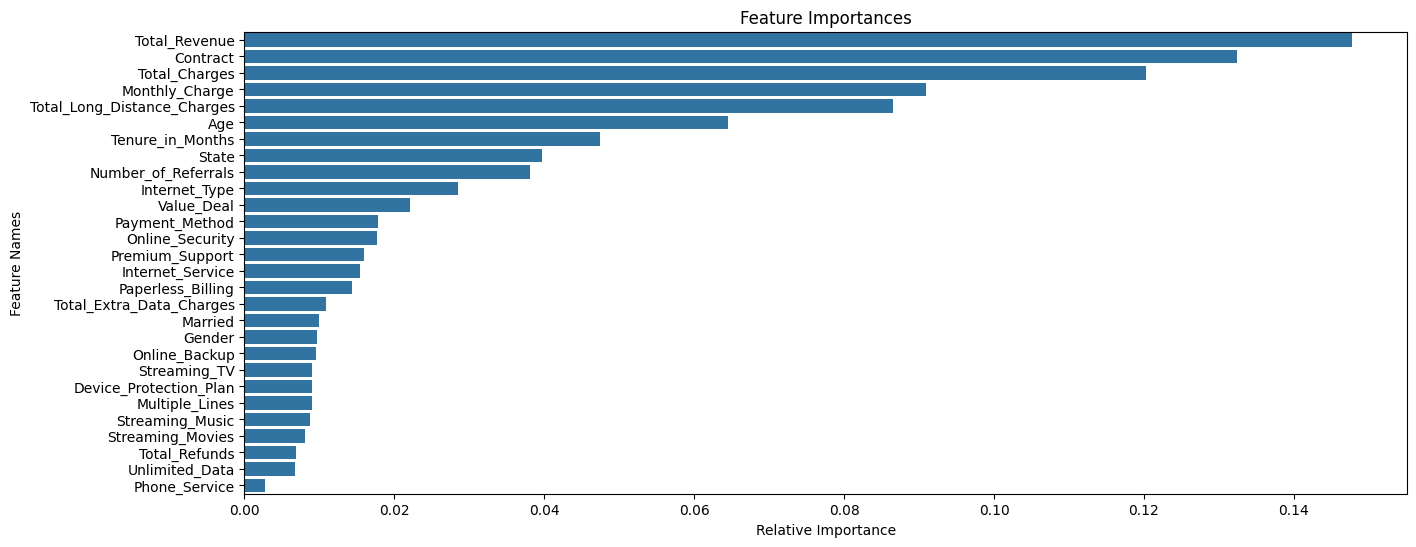

In [14]:
# Plot the feature importances
plt.figure(figsize=(15, 6))
sns.barplot(x=importances[indices], y=X.columns[indices])
plt.title('Feature Importances')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Names')
plt.show()


In [15]:
# Display the first few rows of the prediction data
df_new.head()

,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,18027-UTT,Female,58,Yes,Uttar Pradesh,15,30,Deal 5,Yes,No,...,Credit Card,19.900000,33.700001,0.0,0,7.640000,41.340000,Joined,Others,Others
1,22765-MAH,Female,40,Yes,Maharashtra,6,16,Deal 5,Yes,No,...,Bank Withdrawal,19.450001,19.450001,0.0,0,16.440001,35.889999,Joined,Others,Others
2,22782-ODI,Female,50,Yes,Odisha,2,28,None,Yes,No,...,Credit Card,19.299999,54.700001,0.0,0,30.389999,85.089996,Joined,Others,Others
3,25517-RAJ,Female,40,No,Rajasthan,4,10,None,Yes,Yes,...,Bank Withdrawal,91.449997,171.449997,0.0,10,98.820000,280.269989,Joined,Others,Others
4,27461-MAD,Male,22,Yes,Madhya Pradesh,7,6,Deal 5,Yes,No,...,Credit Card,44.549999,44.549999,0.0,0,23.040001,67.589996,Joined,Others,Others


In [16]:
# Retain the original DataFrame to preserve unencoded columns
original_data = df_new.copy()

In [17]:
# Retain the Customer_ID column
customer_ids = df_new['Customer_ID']


In [20]:
# Drop columns that won't be used for prediction in the encoded DataFrame
new_data = df_new.drop(['Customer_ID', 'Customer_Status', 'Churn_Category', 'Churn_Reason'], axis=1)

# Encode categorical variables using the saved label encoders
for column in new_data.select_dtypes(include=['object']).columns:
    new_data[column] = label_encoders[column].transform(new_data[column])


C:\Users\177r1\AppData\Local\Temp\ipykernel_10624\152325544.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in new_data.select_dtypes(include=['object']).columns:


In [21]:
# Make predictions
new_predictions = rf_model.predict(new_data)


In [22]:
# Add predictions to the original DataFrame
original_data['Customer_Status_Predicted'] = new_predictions


In [23]:
# Filter the DataFrame to include only records predicted as "Churned"
original_data = original_data[original_data['Customer_Status_Predicted'] == 1]


In [24]:
# Save the results
original_data.to_csv(r"C:\Users\177r1\OneDrive\Desktop\PowerBI project\CHURN ML CODE\Prediction.csv", index=False)


In [26]:
original_data.shape

(378, 33)